# E-Commerce Customer Behavior & Sales (2020–2026)

## Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, r2_score, root_mean_squared_error,
)
from sklearn.ensemble import RandomForestRegressor


## Data

In [20]:
buyers = pd.read_csv('C:\\Users\\eveli\\Downloads\\archive\\customers.csv')
buyers

,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0
1,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0
2,C00003,United States,43,Female,Gold,2026-02-08,4,195.37,42.74,0,Home & Kitchen,Mobile,PayPal,Referral,0,4.8,0,0,1,0
3,C00004,United States,41,Male,Free,2025-03-19,6,99.45,15.61,6,Electronics,Desktop,PayPal,Organic Search,2,4.2,0,8,1,0
4,C00005,France,37,Other,Platinum,2024-09-10,36,2593.21,79.09,161,Clothing & Apparel,Tablet,Debit Card,Social Media,9,4.0,4,5,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,C07996,United States,36,Male,Gold,2025-07-09,13,1953.76,175.38,40,Jewelry & Accessories,Tablet,Debit Card,Social Media,1,4.4,1,14,1,1
7996,C07997,India,42,Male,Free,2025-06-28,31,6772.20,251.76,53,Electronics,Mobile,Credit Card,Paid Ad,12,4.6,4,1,0,0
7997,C07998,India,34,Male,Platinum,2026-02-01,46,2430.09,58.01,18,Home & Kitchen,Desktop,Cryptocurrency,Organic Search,9,4.2,6,0,1,0
7998,C07999,Japan,44,Female,Free,2026-01-15,35,5552.56,147.22,50,Food & Grocery,Mobile,Credit Card,Paid Ad,10,4.1,1,2,0,0


In [21]:
orders = pd.read_csv('C:\\Users\\eveli\\Downloads\\archive\\orders.csv')
orders

,order_id,customer_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,quantity,subtotal_usd,discount_pct,discount_amount_usd,shipping_fee_usd,tax_pct,tax_amount_usd,total_amount_usd,payment_method,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer
0,O000001,C07108,2020-08-27,2020,8,Q3,Thursday,Tire Inflator,Automotive,62.91,1,62.91,0,0.00,0.00,18,11.32,74.23,Credit Card,Desktop,3,2020-08-30,Delivered,0,NaN,14.4,1,1
1,O000002,C03487,2024-04-11,2024,4,Q2,Thursday,Stud Earrings Gold,Jewelry & Accessories,18.44,1,18.44,0,0.00,3.99,10,1.84,24.27,Credit Card,Mobile,2,2024-04-13,Delivered,0,NaN,9.0,4,0
2,O000003,C03062,2023-06-25,2023,6,Q2,Sunday,Pen Set Premium,Office Supplies,109.79,1,109.79,20,21.96,0.00,8,7.03,94.86,PayPal,Desktop,3,2023-06-28,Delivered,0,4.0,3.2,17,0
3,O000004,C00888,2020-08-16,2020,8,Q3,Sunday,Smart Watch Series 5,Electronics,87.21,1,87.21,50,43.60,0.00,8,3.49,47.10,Credit Card,Tablet,2,2020-08-18,Returned,1,NaN,32.2,3,1
4,O000005,C01674,2020-04-24,2020,4,Q2,Friday,Stud Earrings Gold,Jewelry & Accessories,94.30,2,188.60,0,0.00,9.99,5,9.43,208.02,Debit Card,Mobile,5,2020-04-29,Delivered,0,2.8,54.7,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,O024996,C07416,2023-03-15,2023,3,Q1,Wednesday,Sports Socks 6-Pack,Clothing & Apparel,59.18,1,59.18,15,8.88,0.00,0,0.00,50.30,Credit Card,Mobile,4,2023-03-19,Delivered,0,NaN,7.9,7,1
24996,O024997,C04387,2024-04-22,2024,4,Q2,Monday,Shower Curtain,Home & Kitchen,81.17,5,405.85,0,0.00,9.99,8,32.47,448.31,Cryptocurrency,Desktop,4,2024-04-26,Delivered,0,NaN,134.7,16,1
24997,O024998,C07566,2023-06-07,2023,6,Q2,Wednesday,Collagen Peptides,Health & Wellness,28.92,5,144.60,0,0.00,6.99,18,26.03,177.62,Credit Card,Desktop,5,2023-06-12,Delivered,0,4.6,4.2,16,1
24998,O024999,C04986,2024-05-06,2024,5,Q2,Monday,Energy Bars 12-Pack,Food & Grocery,19.43,2,38.86,0,0.00,0.00,8,3.11,41.97,Credit Card,Mobile,4,2024-05-10,Delivered,0,4.3,13.5,9,1


## Question

Which gender spends the most money on the platform and on what?

## Analysis

In [22]:
buyers_orders = buyers.merge(orders, on='customer_id')
buyers_orders


,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned,order_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,quantity,subtotal_usd,discount_pct,discount_amount_usd,shipping_fee_usd,tax_pct,tax_amount_usd,total_amount_usd,payment_method,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0,O005822,2025-09-05,2025,9,Q3,Friday,Cycling Gloves,Sports & Outdoors,73.38,5,366.90,0,0.00,0.00,12,44.03,410.93,PayPal,Mobile,2,2025-09-07,Delivered,0,NaN,14.6,2,1
1,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0,O019988,2021-10-05,2021,10,Q4,Tuesday,Smart Plug 4-Pack,Electronics,93.63,1,93.63,0,0.00,6.99,0,0.00,100.62,Credit Card,Mobile,2,2021-10-07,Delivered,0,NaN,3.3,15,0
2,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O004925,2025-12-24,2025,12,Q4,Wednesday,Puzzle 1000pc,Toys & Games,25.89,1,25.89,0,0.00,3.99,18,4.66,34.54,PayPal,Mobile,1,2025-12-25,Cancelled,0,NaN,29.9,2,1
3,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O005852,2023-07-18,2023,7,Q3,Tuesday,LEGO City Set,Toys & Games,32.62,1,32.62,10,3.26,3.99,20,5.87,39.22,UPI / Digital Wallet,Tablet,2,2023-07-20,Delivered,0,NaN,16.8,5,1
4,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O009040,2026-03-30,2026,3,Q1,Monday,Smart Plug 4-Pack,Electronics,346.46,2,692.92,0,0.00,0.00,12,83.15,776.07,PayPal,Mobile,7,2026-04-06,Returned,1,NaN,11.4,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,C07997,India,42,Male,Free,2025-06-28,31,6772.20,251.76,53,Electronics,Mobile,Credit Card,Paid Ad,12,4.6,4,1,0,0,O021457,2021-01-13,2021,1,Q1,Wednesday,Non-stick Pan,Home & Kitchen,42.37,4,169.48,15,25.42,3.99,20,28.81,176.86,UPI / Digital Wallet,Mobile,4,2021-01-17,Delivered,0,NaN,9.8,10,0
24996,C07998,India,34,Male,Platinum,2026-02-01,46,2430.09,58.01,18,Home & Kitchen,Desktop,Cryptocurrency,Organic Search,9,4.2,6,0,1,0,O010838,2025-04-04,2025,4,Q2,Friday,Atomic Habits,Books,14.58,2,29.16,0,0.00,0.00,18,5.25,34.41,PayPal,Mobile,1,2025-04-05,Delivered,0,3.8,14.0,4,1
24997,C07999,Japan,44,Female,Free,2026-01-15,35,5552.56,147.22,50,Food & Grocery,Mobile,Credit Card,Paid Ad,10,4.1,1,2,0,0,O000278,2021-06-01,2021,6,Q2,Tuesday,Yoga Pants,Clothing & Apparel,53.16,1,53.16,20,10.63,0.00,18,7.66,50.19,Debit Card,Mobile,1,2021-06-02,Delivered,0,NaN,19.3,7,1
24998,C07999,Japan,44,Female,Free,2026-01-15,35,5552.56,147.22,50,Food & Grocery,Mobile,Credit Card,Paid Ad,10,4.1,1,2,0,0,O008452,2020-06-27,2020,6,Q2,Saturday,Pet Shampoo Natural,Pet Supplies,13.75,1,13.75,0,0.00,4.99,18,2.48,21.22,UPI / Digital Wallet,Mobile,5,2020-07-02,Returned,1,NaN,4.8,1,1


#### Determining the expenses based on gender

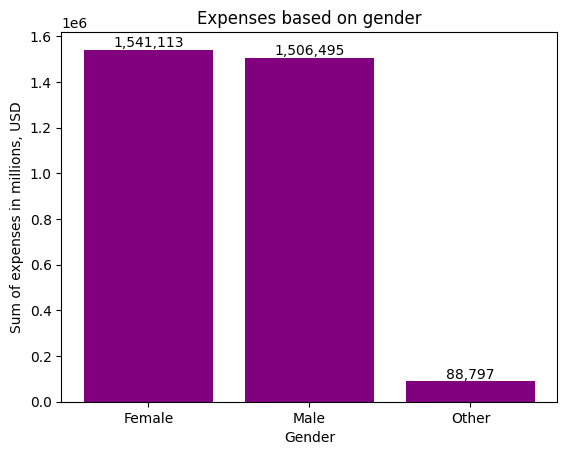

In [8]:
split = buyers_orders.groupby('gender')['total_amount_usd'].sum().reset_index()

column = plt.bar(split['gender'], split['total_amount_usd'], color='purple')
plt.title('Expenses based on gender')
plt.xlabel('Gender')
plt.ylabel('Sum of expenses in millions, USD')
plt.bar_label(column, fmt='{:,.0f}')
plt.show()

Although by a small margin, women spend the most money on the platform.

#### Grouping expenses into categories and determining their distribution.

In [57]:
def category(column):
    if column['total_spend_usd'] < 500:
        return 'up to 500 USD'
    elif column['total_spend_usd'] < 2000:
        return 'from 500 up to 2000 USD'
    else:
        return 'from 2000 USD'
    
buyers_orders['expenses_category'] = buyers_orders.apply(category, axis=1)

buyers_orders

,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned,order_id,order_date,year,month,quarter,day_of_week,product_name,category,unit_price_usd,quantity,subtotal_usd,discount_pct,discount_amount_usd,shipping_fee_usd,tax_pct,tax_amount_usd,total_amount_usd,payment_method,device_used,delivery_days,delivery_date,order_status,returned,customer_rating,session_duration_minutes,pages_viewed_before_purchase,is_repeat_customer,expenses_category
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0,O005822,2025-09-05,2025,9,Q3,Friday,Cycling Gloves,Sports & Outdoors,73.38,5,366.90,0,0.00,0.00,12,44.03,410.93,PayPal,Mobile,2,2025-09-07,Delivered,0,NaN,14.6,2,1,up to 500 USD
1,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0,O019988,2021-10-05,2021,10,Q4,Tuesday,Smart Plug 4-Pack,Electronics,93.63,1,93.63,0,0.00,6.99,0,0.00,100.62,Credit Card,Mobile,2,2021-10-07,Delivered,0,NaN,3.3,15,0,up to 500 USD
2,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O004925,2025-12-24,2025,12,Q4,Wednesday,Puzzle 1000pc,Toys & Games,25.89,1,25.89,0,0.00,3.99,18,4.66,34.54,PayPal,Mobile,1,2025-12-25,Cancelled,0,NaN,29.9,2,1,from 500 up to 2000 USD
3,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O005852,2023-07-18,2023,7,Q3,Tuesday,LEGO City Set,Toys & Games,32.62,1,32.62,10,3.26,3.99,20,5.87,39.22,UPI / Digital Wallet,Tablet,2,2023-07-20,Delivered,0,NaN,16.8,5,1,from 500 up to 2000 USD
4,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0,O009040,2026-03-30,2026,3,Q1,Monday,Smart Plug 4-Pack,Electronics,346.46,2,692.92,0,0.00,0.00,12,83.15,776.07,PayPal,Mobile,7,2026-04-06,Returned,1,NaN,11.4,11,0,from 500 up to 2000 USD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24995,C07997,India,42,Male,Free,2025-06-28,31,6772.20,251.76,53,Electronics,Mobile,Credit Card,Paid Ad,12,4.6,4,1,0,0,O021457,2021-01-13,2021,1,Q1,Wednesday,Non-stick Pan,Home & Kitchen,42.37,4,169.48,15,25.42,3.99,20,28.81,176.86,UPI / Digital Wallet,Mobile,4,2021-01-17,Delivered,0,NaN,9.8,10,0,from 2000 USD
24996,C07998,India,34,Male,Platinum,2026-02-01,46,2430.09,58.01,18,Home & Kitchen,Desktop,Cryptocurrency,Organic Search,9,4.2,6,0,1,0,O010838,2025-04-04,2025,4,Q2,Friday,Atomic Habits,Books,14.58,2,29.16,0,0.00,0.00,18,5.25,34.41,PayPal,Mobile,1,2025-04-05,Delivered,0,3.8,14.0,4,1,from 2000 USD
24997,C07999,Japan,44,Female,Free,2026-01-15,35,5552.56,147.22,50,Food & Grocery,Mobile,Credit Card,Paid Ad,10,4.1,1,2,0,0,O000278,2021-06-01,2021,6,Q2,Tuesday,Yoga Pants,Clothing & Apparel,53.16,1,53.16,20,10.63,0.00,18,7.66,50.19,Debit Card,Mobile,1,2021-06-02,Delivered,0,NaN,19.3,7,1,from 2000 USD
24998,C07999,Japan,44,Female,Free,2026-01-15,35,5552.56,147.22,50,Food & Grocery,Mobile,Credit Card,Paid Ad,10,4.1,1,2,0,0,O008452,2020-06-27,2020,6,Q2,Saturday,Pet Shampoo Natural,Pet Supplies,13.75,1,13.75,0,0.00,4.99,18,2.48,21.22,UPI / Digital Wallet,Mobile,5,2020-07-02,Returned,1,NaN,4.8,1,1,from 2000 USD


In [10]:
buyers_orders.groupby(['gender', 'expenses_category'])['customer_id'].nunique().reset_index()

,gender,expenses_category,customer_id
0,Female,from 2000 USD,881
1,Female,from 500 up to 2000 USD,1606
2,Female,up to 500 USD,1264
3,Male,from 2000 USD,863
4,Male,from 500 up to 2000 USD,1549
5,Male,up to 500 USD,1273
6,Other,from 2000 USD,60
7,Other,from 500 up to 2000 USD,84
8,Other,up to 500 USD,83


Not only do women spend the most on the platform, but more women than men fall into the high-spending category (over 2000 USD).

#### Determining the most popular product categories among men and women.

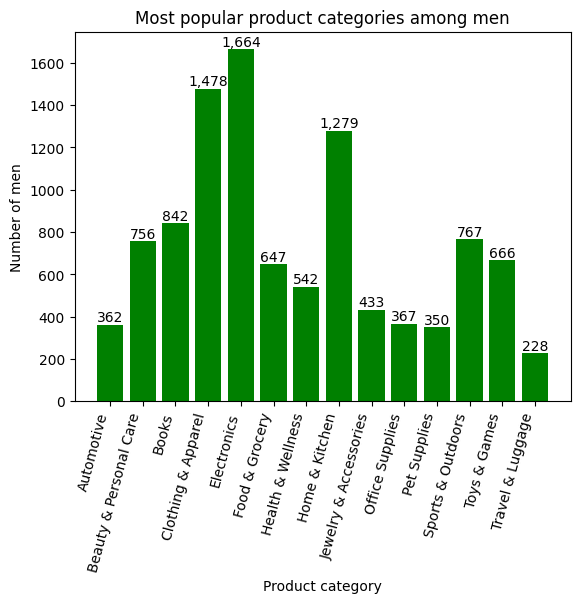

In [12]:
men = buyers_orders.loc[buyers_orders['gender'] == 'Male'].groupby('category')['customer_id'].nunique().reset_index().rename(columns={'customer_id': 'kiekis'})

column = plt.bar(men['category'], men['kiekis'], color='green')
plt.title('Most popular product categories among men')
plt.xlabel('Product category')
plt.ylabel('Number of men')
plt.xticks(rotation=75, ha='right')
plt.bar_label(column, fmt='{:,.0f}')
plt.show()

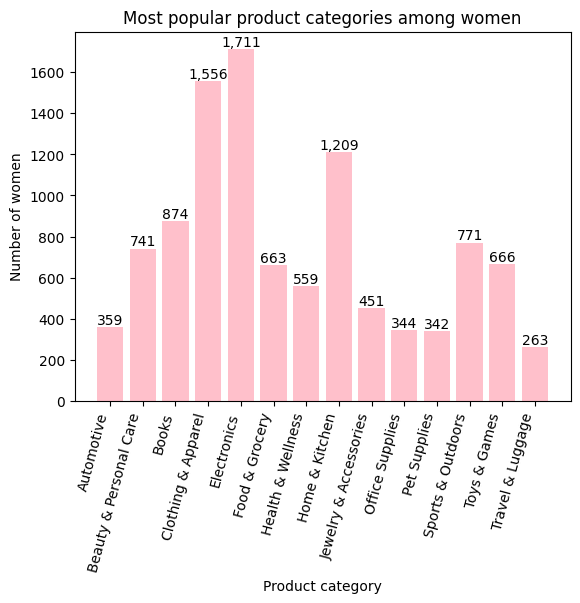

In [14]:
women = buyers_orders.loc[buyers_orders['gender'] == 'Female'].groupby('category')['customer_id'].nunique().reset_index().rename(columns={'customer_id': 'kiekis'})

column = plt.bar(women['category'], women['kiekis'], color='pink')
plt.title('Most popular product categories among women')
plt.xlabel('Product category')
plt.ylabel('Number of women')
plt.xticks(rotation=75, ha='right')
plt.bar_label(column, fmt='{:,.0f}')
plt.show()

We see that the data for women and men is practically the same, so both genders most often buy goods from the electronics and clothing categories.

#### Determining the most popular product in the electronics category.

In [15]:
buyers_orders.loc[buyers_orders['category'] == 'Electronics'].groupby('product_name')['customer_id'].count().reset_index()

,product_name,customer_id
0,Bluetooth Speaker,440
1,Gaming Mouse RGB,461
2,LED Desk Lamp,430
3,Mechanical Keyboard,434
4,Portable Charger 20000mAh,497
5,Smart Plug 4-Pack,466
6,Smart Watch Series 5,451
7,USB-C Hub,449
8,Webcam 4K,452
9,Wireless Earbuds Pro,446


The most popular product in the electronics category is a portable charger.

#### Determining the country that spends the most on the platform.

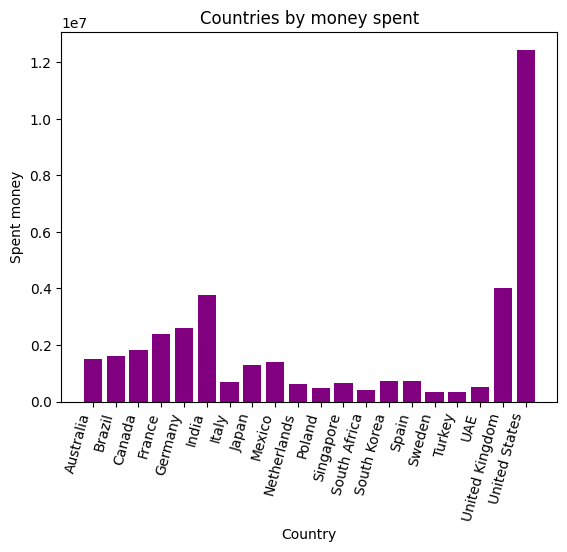

In [16]:
countries = buyers_orders.groupby('country')['total_spend_usd'].sum().reset_index()

column = plt.bar(countries['country'], countries['total_spend_usd'], color='purple')
plt.title('Countries by money spent')
plt.xlabel('Country')
plt.ylabel('Spent money')
plt.xticks(rotation=75, ha='right')
plt.show()

Users from the United States spend the most on the platform.

#### Determining on which day of the week people from United States spend the most money.

In [60]:
buyers_orders.loc[buyers_orders['country'] == 'United States'].groupby('day_of_week')['total_spend_usd'].sum().reset_index()

,day_of_week,total_spend_usd
0,Friday,1907585.32
1,Monday,1685766.69
2,Saturday,1782989.71
3,Sunday,1768137.84
4,Thursday,1797738.49
5,Tuesday,1879974.62
6,Wednesday,1632541.15


People in the US spend the most money on Fridays.

## Conclusion

On the platform women spend the most money, speficially on electronics.

## Identifying trends using Machine Learning.

In [52]:
X = buyers[['gender','total_orders', 'avg_order_value_usd']]
y = buyers.iloc[:, 7]

X = pd.get_dummies(X)

df = X.copy()
df["total_spend_usd"] = y


print("Shape:", df.shape)
df.head()

Shape: (8000, 6)


,total_orders,avg_order_value_usd,gender_Female,gender_Male,gender_Other,total_spend_usd
0,4,63.78,False,True,False,286.63
1,11,107.32,True,False,False,1245.18
2,4,42.74,True,False,False,195.37
3,6,15.61,False,True,False,99.45
4,36,79.09,False,False,True,2593.21


In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (6400, 5) Test: (1600, 5)


In [54]:
rf_reg = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
rf_reg.fit(X_train, y_train)

y_pred_rf = rf_reg.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = root_mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("RandomForestRegressor metrics:")
print(f"MAE:  {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R2:   {r2_rf:.4f}")

RandomForestRegressor metrics:
MAE:  143.1259
RMSE: 401.8367
R2:   0.9679


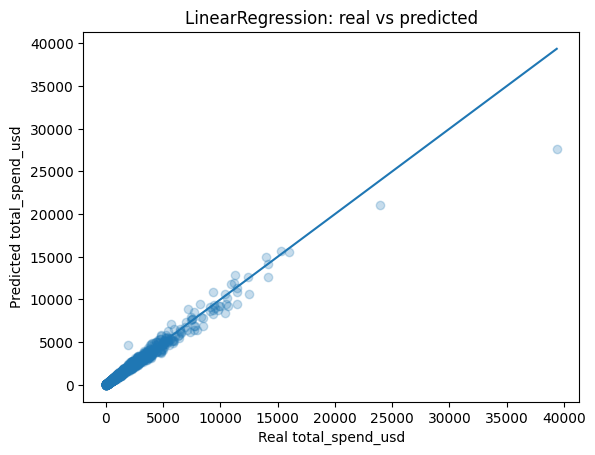

In [56]:
plt.figure()
plt.scatter(y_test, y_pred_rf, alpha=0.25)
plt.xlabel("Real total_spend_usd")
plt.ylabel("Predicted total_spend_usd")
plt.title("LinearRegression: real vs predicted")

mn = min(y_test.min(), y_pred_rf.min())
mx = max(y_test.max(), y_pred_rf.max())
plt.plot([mn, mx], [mn, mx])
plt.show()

